In [1]:
#包和路径
from pathlib import Path
from datetime import datetime, timezone
import re
import traceback

import numpy as np
import pandas as pd
import h5py
import remfile

from dandi.dandiapi import DandiAPIClient
from pynwb import NWBHDF5IO
from tqdm import tqdm

PROJECT_ROOT = Path(
    r"D:\Ephys_analysis\ibl-population-dynamics"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "results"
    / "prototype_sessions"
)

CACHE_DIR = (
    PROJECT_ROOT
    / "cache"
    / "remfile"
)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)
GLOBAL_DIR = (
    PROJECT_ROOT
    / "results"
    / "global_inventory"
)

session_df = pd.read_csv(
    GLOBAL_DIR / "global_session_summary.csv"
)

region_df = pd.read_csv(
    GLOBAL_DIR / "global_region_inventory.csv"
)

trial_df = pd.read_csv(
    GLOBAL_DIR / "global_trial_condition_inventory.csv"
)
DANDISET_ID = "000409"
VERSION = "0.260309.1324"

In [2]:
# Prototype configuration
PROTOTYPE_SESSION = (
    "4d8c7767-981c-4347-8e5e-5d5fffe38534"
)

TARGET_REGION = (
    "Secondary motor area"
)

In [3]:
# Resolve prototype session metadata

prototype_session_matches = (
    session_df.loc[
        session_df["session"]
        .astype(str)
        .eq(PROTOTYPE_SESSION)
    ]
    .copy()
)

if len(prototype_session_matches) != 1:
    raise ValueError(
        f"Expected exactly one session row for "
        f"{PROTOTYPE_SESSION}, "
        f"but found {len(prototype_session_matches)}."
    )

prototype_session_row = (
    prototype_session_matches.iloc[0]
)


SUBJECT = str(
    prototype_session_row["subject"]
)

SESSION = str(
    prototype_session_row["session"]
)

ASSET_PATH = str(
    prototype_session_row["asset_path"]
)


print("Subject:", SUBJECT)
print("Session:", SESSION)
print("Target region:", TARGET_REGION)
print("Asset path:", ASSET_PATH)

print()
print(
    "Whole-session good units:",
    int(prototype_session_row["n_good_units"]),
)

print(
    "Valid trials:",
    int(prototype_session_row["n_valid_trials"]),
)

print(
    "Valid-trial fraction:",
    prototype_session_row["valid_trial_fraction"],
)

print(
    "Median valid RT:",
    prototype_session_row["median_rt_valid_s"],
)

print(
    "Valid-trial accuracy:",
    prototype_session_row["accuracy_valid"],
)

Subject: SWC-038
Session: 4d8c7767-981c-4347-8e5e-5d5fffe38534
Target region: Secondary motor area
Asset path: sub-SWC-038/sub-SWC-038_ses-4d8c7767-981c-4347-8e5e-5d5fffe38534_desc-processed_behavior+ecephys.nwb

Whole-session good units: 389
Valid trials: 545
Valid-trial fraction: 0.7105606258148631
Median valid RT: 0.3035988713700135
Valid-trial accuracy: 0.7541284403669725


In [4]:
# Target-region inventory
prototype_region_rows = (
    region_df.loc[
        region_df["session"]
        .astype(str)
        .eq(PROTOTYPE_SESSION)
        &
        region_df["region_parent"]
        .eq(TARGET_REGION)
    ]
    .copy()
)

if len(prototype_region_rows) == 0:
    raise ValueError(
        f"Target region '{TARGET_REGION}' was not found "
        f"in session {PROTOTYPE_SESSION}."
    )


N_ALL_UNITS_TARGET_REGION = int(
    prototype_region_rows[
        "n_all_units"
    ].sum()
)

N_GOOD_UNITS_TARGET_REGION = int(
    prototype_region_rows[
        "n_good_units"
    ].sum()
)

N_PROBES_TARGET_REGION = int(
    prototype_region_rows[
        "n_probes"
    ].max()
)


print(
    "Target-region all units:",
    N_ALL_UNITS_TARGET_REGION,
)

print(
    "Target-region good units:",
    N_GOOD_UNITS_TARGET_REGION,
)

print(
    "Target-region probes:",
    N_PROBES_TARGET_REGION,
)

print()

display(
    prototype_region_rows[
        [
            "region_raw",
            "region_parent",
            "n_all_units",
            "n_good_units",
            "n_probes",
            "median_firing_rate_hz",
        ]
    ]
    .sort_values(
        "n_good_units",
        ascending=False,
    )
)

Target-region all units: 1262
Target-region good units: 135
Target-region probes: 2



,region_raw,region_parent,n_all_units,n_good_units,n_probes,median_firing_rate_hz
5611,Secondary motor area layer 5,Secondary motor area,675,85,2,2.089607
5612,Secondary motor area layer 6a,Secondary motor area,280,28,2,2.015277
5610,Secondary motor area layer 2/3,Secondary motor area,279,19,2,2.208749
5609,Secondary motor area layer 1,Secondary motor area,28,3,1,3.154507


In [5]:
# Prototype trial inventory:
# collapse over block / choice / reward

prototype_trial_rows = (
    trial_df.loc[
        trial_df["session"]
        .astype(str)
        .eq(PROTOTYPE_SESSION)
    ]
    .copy()
)


prototype_contrast_side_df = (
    prototype_trial_rows
    .groupby(
        [
            "gabor_stimulus_contrast",
            "gabor_stimulus_side",
        ],
        as_index=False,
        dropna=False,
    )
    .agg(
        n_trials=(
            "n_trials",
            "sum",
        ),
        n_valid_trials=(
            "n_valid_trials",
            "sum",
        ),
    )
    .sort_values(
        [
            "gabor_stimulus_contrast",
            "gabor_stimulus_side",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)


display(
    prototype_contrast_side_df
)

ANALYSIS_CONTRASTS = [
    6.25,
    12.5,
    25.0,
    100.0,
]


analysis_trial_inventory_df = (
    prototype_contrast_side_df.loc[
        prototype_contrast_side_df[
            "gabor_stimulus_contrast"
        ].isin(ANALYSIS_CONTRASTS)
    ]
    .copy()
    .reset_index(drop=True)
)

display(
    analysis_trial_inventory_df
)

,gabor_stimulus_contrast,gabor_stimulus_side,n_trials,n_valid_trials
0,100.00,left,96,70
1,100.00,right,73,57
2,25.00,left,97,76
3,25.00,right,87,66
4,12.50,left,84,54
5,12.50,right,71,41
6,6.25,left,81,54
7,6.25,right,84,60
8,0.00,left,50,37
9,0.00,right,44,30


,gabor_stimulus_contrast,gabor_stimulus_side,n_trials,n_valid_trials
0,100.00,left,96,70
1,100.00,right,73,57
2,25.00,left,97,76
3,25.00,right,87,66
4,12.50,left,84,54
5,12.50,right,71,41
6,6.25,left,81,54
7,6.25,right,84,60


In [6]:
# Prototype summary

print("=" * 70)

print(
    f"Subject:       {SUBJECT}"
)

print(
    f"Session:       {SESSION}"
)

print(
    f"Target region: {TARGET_REGION}"
)

print(
    f"Good units:    "
    f"{N_GOOD_UNITS_TARGET_REGION}"
)

print(
    f"Valid trials:  "
    f"{int(prototype_session_row['n_valid_trials'])}"
)

print("=" * 70)

display(
    analysis_trial_inventory_df
)

Subject:       SWC-038
Session:       4d8c7767-981c-4347-8e5e-5d5fffe38534
Target region: Secondary motor area
Good units:    135
Valid trials:  545


,gabor_stimulus_contrast,gabor_stimulus_side,n_trials,n_valid_trials
0,100.00,left,96,70
1,100.00,right,73,57
2,25.00,left,97,76
3,25.00,right,87,66
4,12.50,left,84,54
5,12.50,right,71,41
6,6.25,left,81,54
7,6.25,right,84,60


In [7]:
# 定义远程打开 NWB
# 访问逻辑来自 02_global_session_inventory.ipynb，

def open_remote_nwb(
    asset_path,
    dandiset,
    cache_dir,
):
    """
    Open one remote NWB file through DANDI + remfile.

    Parameters
    ----------
    asset_path : str
        Path of the NWB asset within the Dandiset.

    dandiset
        DANDI dandiset object obtained from DandiAPIClient.

    cache_dir : pathlib.Path
        Local disk-cache directory.

    Returns
    -------
    rem_file
        Remote file object with local disk caching.

    h5py_file
        HDF5 file interface.

    io
        PyNWB input/output interface.

    nwbfile
        Loaded NWBFile object.
    """

    rem_file = None
    h5py_file = None
    io = None

    try:
        # 1. 根据 asset_path 找到 DANDI 里的文件
        asset = dandiset.get_asset_by_path(
            path=str(asset_path)
        )

        # 2. 获取实际的远程 S3 地址
        s3_url = asset.get_content_url(
            follow_redirects=1,
            strip_query=True,
        )

        # 3. 设置本地硬盘缓存
        disk_cache = remfile.DiskCache(
            str(cache_dir)
        )

        # 4. 建立支持远程按需读取的文件对象
        rem_file = remfile.File(
            s3_url,
            disk_cache=disk_cache,
        )

        # 5. 让 h5py 把远程文件作为 HDF5 打开
        h5py_file = h5py.File(
            rem_file,
            mode="r",
        )

        # 6. 用 PyNWB 读取 NWB 结构
        io = NWBHDF5IO(
            file=h5py_file,
            load_namespaces=True,
        )

        nwbfile = io.read()

        return (
            rem_file,
            h5py_file,
            io,
            nwbfile,
        )

    except Exception:
        # 如果打开过程在中途失败，
        # 关闭此前已经成功创建的资源。
        for obj in (
            io,
            h5py_file,
            rem_file,
        ):
            if obj is not None:
                try:
                    obj.close()
                except Exception:
                    pass

        raise

In [8]:
#打开
client = DandiAPIClient()

dandiset = client.get_dandiset(
    dandiset_id=DANDISET_ID,
    version_id=VERSION,
)

(
    rem_file,
    h5py_file,
    io,
    nwbfile,
) = open_remote_nwb(
    asset_path=ASSET_PATH,
    dandiset=dandiset,
    cache_dir=CACHE_DIR,
)

print("Opened subject:", SUBJECT)
print("Opened session:", SESSION)
print("NWB identifier:", nwbfile.identifier)

Opened subject: SWC-038
Opened session: 4d8c7767-981c-4347-8e5e-5d5fffe38534
NWB identifier: f7205118-eed2-4ddc-a0eb-2c75583fa2ee


In [9]:
#NWB基本结构
units_raw_df = (
    nwbfile.units
    .to_dataframe()
)

trials_raw_df = (
    nwbfile.trials
    .to_dataframe()
)

electrodes_raw_df = (
    nwbfile.electrodes
    .to_dataframe()
)

#规模
print(
    "Units:",
    units_raw_df.shape,
)

print(
    "Trials:",
    trials_raw_df.shape,
)

print(
    "Electrodes:",
    electrodes_raw_df.shape,
)

#列名
print("\nUnit columns:")
print(units_raw_df.columns.tolist())

print("\nTrial columns:")
print(trials_raw_df.columns.tolist())

print("\nElectrode columns:")
print(electrodes_raw_df.columns.tolist())

display(units_raw_df.head())
display(trials_raw_df.head())
display(electrodes_raw_df.head())

Units: (3119, 27)
Trials: (767, 17)
Electrodes: (768, 18)

Unit columns:
['unit_name', 'firing_rate', 'waveform_mean', 'rp_violation', 'kilosort2_label', 'presence_ratio_std', 'spike_distances_from_probe_tip_um', 'missed_spikes_estimate', 'presence_ratio', 'isi_violations_ratio', 'probe_name', 'spike_count', 'spike_amplitude_std_dB', 'noise_cutoff', 'cluster_uuid', 'median_spike_amplitude_uV', 'sliding_rp_violation', 'spike_amplitudes_uV', 'distance_from_probe_tip_um', 'electrodes', 'ibl_quality_score', 'peak_to_trough_duration_ms', 'spike_times', 'max_electrode', 'max_spike_amplitude_uV', 'cumulative_drift_um_per_hour', 'min_spike_amplitude_uV']

Trial columns:
['start_time', 'stop_time', 'quiescence_period', 'gabor_stimulus_onset_time', 'auditory_cue_time', 'wheel_movement_onset_time', 'choice_registration_time', 'feedback_time', 'gabor_stimulus_offset_time', 'gabor_stimulus_contrast', 'gabor_stimulus_side', 'mouse_wheel_choice', 'is_mouse_rewarded', 'reward_volume_uL', 'probability_

,unit_name,firing_rate,waveform_mean,rp_violation,kilosort2_label,presence_ratio_std,spike_distances_from_probe_tip_um,missed_spikes_estimate,presence_ratio,isi_violations_ratio,...,spike_amplitudes_uV,distance_from_probe_tip_um,electrodes,ibl_quality_score,peak_to_trough_duration_ms,spike_times,max_electrode,max_spike_amplitude_uV,cumulative_drift_um_per_hour,min_spike_amplitude_uV
id,,,,,,,,,,,,,,,,,,,,,
0,probe00_0,4.772794,"[[1.2744501e-06, -4.5322514e-07, 7.5261585e-07...",0.095048,mua,8.637136,"[85.26221466064453, 102.42929077148438, 118.73...",0.500000,1.0,0.108739,...,"[31.068726358167442, 29.3699175280401, 29.1694...",20.0,location \ id ...,0.333333,0.599992,"[0.017463363915093195, 0.5961917213221114, 0.6...",location \ id ...,68.328994,547542.935060,24.990246
1,probe00_1,4.982093,"[[-8.2915665e-07, -1.8957078e-06, 2.2482404e-0...",0.089832,mua,10.705453,"[176.86695861816406, 177.07098388671875, 211.7...",0.321506,1.0,0.102353,...,"[19.08529263262846, 21.071693466970128, 23.450...",20.0,location \ id ...,0.333333,-0.733324,"[0.16359544079980506, 0.35346047500037964, 0.5...",location \ id ...,59.770196,400890.165355,18.102430
2,probe00_2,4.222429,"[[2.0584262e-06, -4.0506457e-08, -4.2534884e-0...",0.041496,mua,7.992847,"[121.3042984008789, 176.838623046875, 173.2538...",0.500000,1.0,0.042749,...,"[22.92462275077964, 24.78606442112987, 24.5831...",20.0,location \ id ...,0.333333,0.833322,"[0.22616156952074584, 0.2829944142033265, 0.53...",location \ id ...,50.296216,614840.500080,20.175390
3,probe00_3,4.998808,"[[-1.2087576e-08, 7.9012455e-07, 1.8333617e-06...",0.068796,mua,9.458360,"[108.21451568603516, 190.1461944580078, 114.14...",0.439039,1.0,0.076252,...,"[25.75496428652748, 29.04126668114557, 28.0132...",20.0,location \ id ...,0.333333,0.699991,"[0.4010267326907272, 0.7186906680719554, 0.954...",location \ id ...,88.716774,644939.334353,21.750958
4,probe00_4,4.520995,"[[-3.0998187e-06, -4.2328077e-07, -3.2543248e-...",0.087959,mua,7.827280,"[159.25753784179688, 189.39503479003906, 200.7...",0.500000,1.0,0.099437,...,"[25.357481533418987, 26.013051292920863, 24.89...",20.0,location \ id ...,0.333333,-0.666658,"[0.09662934990989035, 0.18459526024263548, 0.6...",location \ id ...,49.674859,445951.189895,19.720945


,start_time,stop_time,quiescence_period,gabor_stimulus_onset_time,auditory_cue_time,wheel_movement_onset_time,choice_registration_time,feedback_time,gabor_stimulus_offset_time,gabor_stimulus_contrast,gabor_stimulus_side,mouse_wheel_choice,is_mouse_rewarded,reward_volume_uL,probability_left,block_type,block_index
id,,,,,,,,,,,,,,,,,
0,132.102522,144.079814,0.610104,141.513147,141.514047,142.280511,142.490700,142.490783,143.579707,100.00,left,clockwise,True,1.5,0.5,unbiased,0
1,144.503115,158.723109,0.603376,145.189913,145.191013,151.786511,157.137196,157.137285,158.223043,12.50,left,clockwise,True,1.5,0.5,unbiased,0
2,159.219810,162.196140,0.618698,160.279104,160.280204,160.437511,160.607722,160.607838,161.696095,100.00,left,clockwise,True,1.5,0.5,unbiased,0
3,162.579740,167.422982,0.559975,163.223143,163.224143,163.958511,164.835659,164.836481,166.922973,6.25,right,clockwise,False,0.0,0.5,unbiased,0
4,167.821483,170.546406,0.674887,168.579274,168.580074,168.833511,168.959991,168.960102,170.046394,25.00,left,clockwise,True,1.5,0.5,unbiased,0


,location,group,electrode_name,contact_shapes,channel_name,rel_x,rel_y,probe_name,contact_ids,shank_ids,adc_group,adc_sample_order,group_name,x,y,z,imp,filtering
id,,,,,,,,,,,,,,,,,,
0,Anterior olfactory nucleus,Probe01 pynwb.ecephys.ElectrodeGroup at 0x2013...,e0,square,"AP0,LF0",16.0,0.0,Probe01,e0,,0,0,Probe01,3641.0,5362.0,5223.0,NaN,
1,Anterior olfactory nucleus,Probe01 pynwb.ecephys.ElectrodeGroup at 0x2013...,e1,square,"AP1,LF1",48.0,0.0,Probe01,e1,,1,0,Probe01,3641.0,5362.0,5223.0,NaN,
2,Anterior olfactory nucleus,Probe01 pynwb.ecephys.ElectrodeGroup at 0x2013...,e2,square,"AP2,LF2",0.0,20.0,Probe01,e2,,0,1,Probe01,3644.0,5343.0,5216.0,NaN,
3,Anterior olfactory nucleus,Probe01 pynwb.ecephys.ElectrodeGroup at 0x2013...,e3,square,"AP3,LF3",32.0,20.0,Probe01,e3,,1,1,Probe01,3644.0,5343.0,5216.0,NaN,
4,Anterior olfactory nucleus,Probe01 pynwb.ecephys.ElectrodeGroup at 0x2013...,e4,square,"AP4,LF4",16.0,40.0,Probe01,e4,,0,2,Probe01,3647.0,5324.0,5210.0,NaN,


In [10]:
# ============================================================
# 检查 Unit、Trial 和 Electrode 表的关键字段
#
# 目的：
# 1. 确认 probe 数量
# 2. 确认 unit QC 标签的实际写法
# 3. 确认 trial 中 left/right、choice、reward 的编码
# 4. 确认 max_electrode 能否映射到 electrode 表
# ============================================================

print("Unit index name:", units_raw_df.index.name)
print("Trial index name:", trials_raw_df.index.name)
print("Electrode index name:", electrodes_raw_df.index.name)


# ------------------------------------------------------------
# 1. 查看 probe 构成
# ------------------------------------------------------------

print("\nUnits per probe:")

display(
    units_raw_df[
        "probe_name"
    ].value_counts(
        dropna=False
    )
)

print("\nElectrodes per probe:")

display(
    electrodes_raw_df[
        "probe_name"
    ].value_counts(
        dropna=False
    )
)


# ------------------------------------------------------------
# 2. 查看 unit QC 标签
# ------------------------------------------------------------

print("\nIBL quality scores:")

display(
    units_raw_df[
        "ibl_quality_score"
    ].value_counts(
        dropna=False
    )
)

print("\nKilosort labels:")

display(
    units_raw_df[
        "kilosort2_label"
    ].value_counts(
        dropna=False
    )
)


# ------------------------------------------------------------
# 3. 查看 trial 条件的实际编码
# ------------------------------------------------------------

trial_label_columns = [
    "gabor_stimulus_contrast",
    "gabor_stimulus_side",
    "mouse_wheel_choice",
    "is_mouse_rewarded",
    "probability_left",
    "block_type",
]

for column in trial_label_columns:
    print(f"\n{column}:")

    display(
        trials_raw_df[column]
        .value_counts(
            dropna=False
        )
    )


# ------------------------------------------------------------
# 4. 检查关键时间列的缺失情况
# ------------------------------------------------------------

trial_time_columns = [
    "gabor_stimulus_onset_time",
    "wheel_movement_onset_time",
    "choice_registration_time",
    "feedback_time",
    "gabor_stimulus_offset_time",
]

timing_missing_df = pd.DataFrame(
    {
        "n_missing": (
            trials_raw_df[
                trial_time_columns
            ]
            .isna()
            .sum()
        ),
        "missing_fraction": (
            trials_raw_df[
                trial_time_columns
            ]
            .isna()
            .mean()
        ),
    }
)

display(timing_missing_df)


# ------------------------------------------------------------
# 5. 检查 max_electrode 是否对应 electrode index
# ------------------------------------------------------------

max_electrode_values = pd.to_numeric(
    units_raw_df[
        "max_electrode"
    ],
    errors="coerce",
)

non_missing_max_electrode = (
    max_electrode_values
    .dropna()
)

mapping_fraction = (
    non_missing_max_electrode
    .isin(electrodes_raw_df.index)
    .mean()
)

print(
    "\nUnits with non-missing max_electrode:",
    len(non_missing_max_electrode),
)

print(
    "Fraction mapping to electrode index:",
    mapping_fraction,
)


# ------------------------------------------------------------
# 6. 查看几行关键 unit 信息
# ------------------------------------------------------------

display(
    units_raw_df[
        [
            "unit_name",
            "probe_name",
            "max_electrode",
            "ibl_quality_score",
            "kilosort2_label",
            "firing_rate",
            "spike_count",
        ]
    ]
    .head(10)
)

Unit index name: id
Trial index name: id
Electrode index name: id

Units per probe:


probe_name
Probe00    1664
Probe01    1455
Name: count, dtype: int64


Electrodes per probe:


probe_name
Probe01    384
Probe00    384
Name: count, dtype: int64


IBL quality scores:


ibl_quality_score
0.333333    1363
0.000000     757
0.666667     610
1.000000     389
Name: count, dtype: int64

... (13 outputs left out)

block_type
left_block     355
right_block    322
unbiased        90
Name: count, dtype: int64

,n_missing,missing_fraction
gabor_stimulus_onset_time,0,0.000000
wheel_movement_onset_time,2,0.002608
choice_registration_time,0,0.000000
feedback_time,0,0.000000
gabor_stimulus_offset_time,0,0.000000



Units with non-missing max_electrode: 0
Fraction mapping to electrode index: nan


,unit_name,probe_name,max_electrode,ibl_quality_score,kilosort2_label,firing_rate,spike_count
id,,,,,,,
0,probe00_0,Probe00,location \ id ...,0.333333,mua,4.772794,26840
1,probe00_1,Probe00,location \ id ...,0.333333,mua,4.982093,28017
2,probe00_2,Probe00,location \ id ...,0.333333,mua,4.222429,23745
3,probe00_3,Probe00,location \ id ...,0.333333,mua,4.998808,28111
4,probe00_4,Probe00,location \ id ...,0.333333,mua,4.520995,25424
5,probe00_5,Probe00,location \ id ...,0.333333,mua,3.908214,21978
6,probe00_6,Probe00,location \ id ...,0.333333,mua,4.547669,25574
7,probe00_7,Probe00,location \ id ...,0.333333,good,3.887586,21862
8,probe00_8,Probe00,location \ id ...,0.333333,mua,4.542334,25544


In [11]:
# 查看第一个 unit 的 max_electrode 对象

sample_max_electrode = (
    units_raw_df["max_electrode"].iloc[0]
)

print(
    "Python type:",
    type(sample_max_electrode),
)

display(sample_max_electrode)

if isinstance(
    sample_max_electrode,
    pd.DataFrame,
):
    print(
        "Shape:",
        sample_max_electrode.shape,
    )

    print(
        "Index:",
        sample_max_electrode.index.tolist(),
    )

    print(
        "Columns:",
        sample_max_electrode.columns.tolist(),
    )

Python type: <class 'pandas.DataFrame'>


,location,group,electrode_name,contact_shapes,channel_name,rel_x,rel_y,probe_name,contact_ids,shank_ids,adc_group,adc_sample_order,group_name,x,y,z,imp,filtering
id,,,,,,,,,,,,,,,,,,
384,Taenia tecta dorsal part,Probe00 pynwb.ecephys.ElectrodeGroup at 0x2013...,e0,square,"AP0,LF0",16.0,0.0,Probe00,e0,,0,0,Probe00,3622.0,5208.0,6083.0,NaN,


Shape: (1, 18)
Index: [384]
Columns: ['location', 'group', 'electrode_name', 'contact_shapes', 'channel_name', 'rel_x', 'rel_y', 'probe_name', 'contact_ids', 'shank_ids', 'adc_group', 'adc_sample_order', 'group_name', 'x', 'y', 'z', 'imp', 'filtering']


In [12]:
# ============================================================
# 从每个 unit 的 max_electrode 嵌套 DataFrame 中，
# 提取代表性 electrode 的 ID、脑区、probe 和坐标
# ============================================================

def extract_max_electrode_metadata(max_electrode_object):
    """
    从一个 unit 的 max_electrode 对象中提取
    代表性 electrode 的基本信息。
    """

    # 如果不是有效的一行 DataFrame，则返回缺失值
    if (
        not isinstance(max_electrode_object, pd.DataFrame)
        or max_electrode_object.empty
    ):
        return pd.Series(
            {
                "max_electrode_id": pd.NA,
                "region_raw": pd.NA,
                "max_electrode_probe_name": pd.NA,
                "electrode_x": np.nan,
                "electrode_y": np.nan,
                "electrode_z": np.nan,
            }
        )

    # 这张嵌套表正常情况下只有一行
    electrode_id = max_electrode_object.index[0]
    electrode_row = max_electrode_object.iloc[0]

    return pd.Series(
        {
            "max_electrode_id": electrode_id,
            "region_raw": electrode_row.get(
                "location",
                pd.NA,
            ),
            "max_electrode_probe_name": electrode_row.get(
                "probe_name",
                pd.NA,
            ),
            "electrode_x": electrode_row.get(
                "x",
                np.nan,
            ),
            "electrode_y": electrode_row.get(
                "y",
                np.nan,
            ),
            "electrode_z": electrode_row.get(
                "z",
                np.nan,
            ),
        }
    )


max_electrode_metadata_df = (
    units_raw_df["max_electrode"]
    .apply(extract_max_electrode_metadata)
)

display(
    max_electrode_metadata_df.head(10)
)

#验证
print(
    "Units with resolved max electrode:",
    int(
        max_electrode_metadata_df[
            "max_electrode_id"
        ]
        .notna()
        .sum()
    ),
)

print(
    "Units with region label:",
    int(
        max_electrode_metadata_df[
            "region_raw"
        ]
        .notna()
        .sum()
    ),
)

display(
    max_electrode_metadata_df[
        "region_raw"
    ]
    .value_counts(
        dropna=False
    )
    .head(20)
)

,max_electrode_id,region_raw,max_electrode_probe_name,electrode_x,electrode_y,electrode_z
id,,,,,,
0,384,Taenia tecta dorsal part,Probe00,3622.0,5208.0,6083.0
1,384,Taenia tecta dorsal part,Probe00,3622.0,5208.0,6083.0
2,384,Taenia tecta dorsal part,Probe00,3622.0,5208.0,6083.0
3,384,Taenia tecta dorsal part,Probe00,3622.0,5208.0,6083.0
4,384,Taenia tecta dorsal part,Probe00,3622.0,5208.0,6083.0
5,384,Taenia tecta dorsal part,Probe00,3622.0,5208.0,6083.0
6,384,Taenia tecta dorsal part,Probe00,3622.0,5208.0,6083.0
7,384,Taenia tecta dorsal part,Probe00,3622.0,5208.0,6083.0
8,384,Taenia tecta dorsal part,Probe00,3622.0,5208.0,6083.0


Units with resolved max electrode: 3119
Units with region label: 3119


region_raw
Secondary motor area layer 5                    675
Orbital area medial part layer 6a               353
Taenia tecta dorsal part                        345
Orbital area ventrolateral part layer 6a        324
Dorsal peduncular area                          293
Secondary motor area layer 6a                   280
Secondary motor area layer 2/3                  279
Anterior olfactory nucleus                      191
Infralimbic area layer 6a                       138
Prelimbic area layer 6a                         136
Olfactory areas                                  37
Frontal pole layer 6a                            33
Secondary motor area layer 1                     28
Anterior cingulate area dorsal part layer 6a      7
Name: count, dtype: int64

In [13]:
#和electrode表比较
display(
    electrodes_raw_df.loc[[0]]
)

#unit的 max_electrode嵌套表 与 nwbfile.electrodes完整表 相互对应

,location,group,electrode_name,contact_shapes,channel_name,rel_x,rel_y,probe_name,contact_ids,shank_ids,adc_group,adc_sample_order,group_name,x,y,z,imp,filtering
id,,,,,,,,,,,,,,,,,,
0,Anterior olfactory nucleus,Probe01 pynwb.ecephys.ElectrodeGroup at 0x2013...,e0,square,"AP0,LF0",16.0,0.0,Probe01,e0,,0,0,Probe01,3641.0,5362.0,5223.0,NaN,


In [14]:
unit_metadata_df = (
    units_raw_df
    .reset_index()
    .rename(
        columns={
            "id": "unit_index",
        }
    )
    [
        [
            "unit_index",
            "unit_name",
            "probe_name",
            "ibl_quality_score",
            "kilosort2_label",
            "firing_rate",
            "spike_count",
        ]
    ]
    .copy()
)

unit_metadata_df = pd.concat(
    [
        unit_metadata_df.reset_index(
            drop=True
        ),
        max_electrode_metadata_df.reset_index(
            drop=True
        ),
    ],
    axis=1,
)

display(
    unit_metadata_df.head()
)

,unit_index,unit_name,probe_name,ibl_quality_score,kilosort2_label,firing_rate,spike_count,max_electrode_id,region_raw,max_electrode_probe_name,electrode_x,electrode_y,electrode_z
0,0,probe00_0,Probe00,0.333333,mua,4.772794,26840,384,Taenia tecta dorsal part,Probe00,3622.0,5208.0,6083.0
1,1,probe00_1,Probe00,0.333333,mua,4.982093,28017,384,Taenia tecta dorsal part,Probe00,3622.0,5208.0,6083.0
2,2,probe00_2,Probe00,0.333333,mua,4.222429,23745,384,Taenia tecta dorsal part,Probe00,3622.0,5208.0,6083.0
3,3,probe00_3,Probe00,0.333333,mua,4.998808,28111,384,Taenia tecta dorsal part,Probe00,3622.0,5208.0,6083.0
4,4,probe00_4,Probe00,0.333333,mua,4.520995,25424,384,Taenia tecta dorsal part,Probe00,3622.0,5208.0,6083.0


In [15]:
# 清理文本、合并皮层 layer，并建立 good-unit 标签
import re


def clean_text(value):
    """
    将文本统一转换为去除首尾空格的字符串。
    缺失值保留为 pd.NA。
    """
    if pd.isna(value):
        return pd.NA

    if isinstance(value, bytes):
        return (
            value
            .decode(
                "utf-8",
                errors="replace",
            )
            .strip()
        )

    return str(value).strip()


def collapse_cortical_layer(region_name):
    """
    删除脑区名称末尾的 cortical layer 后缀。

    例如：
    Primary visual area, layer 4
    → Primary visual area

    非皮层分层名称保持不变。
    """
    if pd.isna(region_name):
        return pd.NA

    region_name = str(region_name).strip()

    layer_pattern = (
        r",?\s+layer\s+"
        r"(?:2/3|6a|6b|1|2|3|4|5|6)$"
    )

    region_parent = re.sub(
        layer_pattern,
        "",
        region_name,
        flags=re.IGNORECASE,
    )

    return region_parent.strip()


# ------------------------------------------------------------
# 1. 清理文本列
# ------------------------------------------------------------

text_columns = [
    "unit_name",
    "probe_name",
    "kilosort2_label",
    "region_raw",
    "max_electrode_probe_name",
]

for column in text_columns:
    unit_metadata_df[column] = (
        unit_metadata_df[column]
        .apply(clean_text)
        .astype("string")
    )


# ------------------------------------------------------------
# 2. 建立不包含 layer 的 parent-region 名称
# ------------------------------------------------------------

unit_metadata_df["region_parent"] = (
    unit_metadata_df["region_raw"]
    .apply(collapse_cortical_layer)
    .astype("string")
)


# ------------------------------------------------------------
# 3. 将质量分数转成数值
# ------------------------------------------------------------

unit_metadata_df["ibl_quality_score"] = (
    pd.to_numeric(
        unit_metadata_df["ibl_quality_score"],
        errors="coerce",
    )
)


# ------------------------------------------------------------
# 4. 使用与 global inventory 完全相同的规则
# ------------------------------------------------------------

GOOD_UNIT_SCORE = 1.0

unit_metadata_df["is_good_unit"] = (
    unit_metadata_df["ibl_quality_score"]
    .eq(GOOD_UNIT_SCORE)
)


display(
    unit_metadata_df[
        [
            "unit_index",
            "unit_name",
            "probe_name",
            "max_electrode_id",
            "region_raw",
            "region_parent",
            "ibl_quality_score",
            "is_good_unit",
            "firing_rate",
        ]
    ].head(10)
)

,unit_index,unit_name,probe_name,max_electrode_id,region_raw,region_parent,ibl_quality_score,is_good_unit,firing_rate
0,0,probe00_0,Probe00,384,Taenia tecta dorsal part,Taenia tecta dorsal part,0.333333,False,4.772794
1,1,probe00_1,Probe00,384,Taenia tecta dorsal part,Taenia tecta dorsal part,0.333333,False,4.982093
2,2,probe00_2,Probe00,384,Taenia tecta dorsal part,Taenia tecta dorsal part,0.333333,False,4.222429
3,3,probe00_3,Probe00,384,Taenia tecta dorsal part,Taenia tecta dorsal part,0.333333,False,4.998808
4,4,probe00_4,Probe00,384,Taenia tecta dorsal part,Taenia tecta dorsal part,0.333333,False,4.520995
5,5,probe00_5,Probe00,384,Taenia tecta dorsal part,Taenia tecta dorsal part,0.333333,False,3.908214
6,6,probe00_6,Probe00,384,Taenia tecta dorsal part,Taenia tecta dorsal part,0.333333,False,4.547669
7,7,probe00_7,Probe00,384,Taenia tecta dorsal part,Taenia tecta dorsal part,0.333333,False,3.887586
8,8,probe00_8,Probe00,384,Taenia tecta dorsal part,Taenia tecta dorsal part,0.333333,False,4.542334
9,9,probe00_9,Probe00,384,Taenia tecta dorsal part,Taenia tecta dorsal part,0.333333,False,4.594081


In [16]:
# 检查 unit metadata 是否与 global inventory 一致

print(
    "Total units:",
    len(unit_metadata_df),
)

print(
    "Whole-session good units:",
    int(
        unit_metadata_df[
            "is_good_unit"
        ].sum()
    ),
)

print(
    "Units with max electrode:",
    int(
        unit_metadata_df[
            "max_electrode_id"
        ].notna()
        .sum()
    ),
)

print(
    "Units with region label:",
    int(
        unit_metadata_df[
            "region_raw"
        ].notna()
        .sum()
    ),
)


# 检查 unit probe 与 max-electrode probe 是否一致
probe_agreement = (
    unit_metadata_df["probe_name"]
    .eq(
        unit_metadata_df[
            "max_electrode_probe_name"
        ]
    )
)

print(
    "Probe-name agreement:",
    probe_agreement.mean(),
)

Total units: 3119
Whole-session good units: 389
Units with max electrode: 3119
Units with region label: 3119
Probe-name agreement: 1.0


In [17]:
#MOs good units
selected_units_df = (
    unit_metadata_df.loc[
        unit_metadata_df["is_good_unit"]
        & unit_metadata_df["region_parent"]
        .eq(TARGET_REGION)
    ]
    .copy()
    .sort_values("unit_index")
    .reset_index(drop=True)
)

print(
    "Selected VISp good units:",
    len(selected_units_df),
)

display(
    selected_units_df[
        [
            "unit_index",
            "unit_name",
            "probe_name",
            "max_electrode_id",
            "region_raw",
            "region_parent",
            "ibl_quality_score",
            "kilosort2_label",
            "firing_rate",
            "spike_count",
        ]
    ].head(20)
)

Selected VISp good units: 135


,unit_index,unit_name,probe_name,max_electrode_id,region_raw,region_parent,ibl_quality_score,kilosort2_label,firing_rate,spike_count
0,1048,probe00_1048,Probe00,655,Secondary motor area layer 6a,Secondary motor area,1.0,good,0.705961,3970
1,1050,probe00_1050,Probe00,656,Secondary motor area layer 6a,Secondary motor area,1.0,good,0.425533,2393
2,1051,probe00_1051,Probe00,656,Secondary motor area layer 6a,Secondary motor area,1.0,good,0.182803,1028
3,1065,probe00_1065,Probe00,662,Secondary motor area layer 6a,Secondary motor area,1.0,good,5.246517,29504
4,1069,probe00_1069,Probe00,663,Secondary motor area layer 6a,Secondary motor area,1.0,good,2.015278,11333
5,1074,probe00_1074,Probe00,670,Secondary motor area layer 6a,Secondary motor area,1.0,good,0.449005,2525
6,1075,probe00_1075,Probe00,669,Secondary motor area layer 6a,Secondary motor area,1.0,good,0.961850,5409
7,1082,probe00_1082,Probe00,671,Secondary motor area layer 6a,Secondary motor area,1.0,good,2.073782,11662
8,1089,probe00_1089,Probe00,673,Secondary motor area layer 6a,Secondary motor area,1.0,good,0.753796,4239
9,1097,probe00_1097,Probe00,680,Secondary motor area layer 5,Secondary motor area,1.0,good,0.842174,4736


In [22]:
#核对
expected_n_good_units = (
    N_GOOD_UNITS_TARGET_REGION
)

actual_n_good_units = len(
    selected_units_df
)


print(
    "Target region:",
    TARGET_REGION,
)

print(
    "Expected from global region inventory:",
    expected_n_good_units,
)

print(
    "Extracted from NWB:",
    actual_n_good_units,
)


assert (
    actual_n_good_units
    == expected_n_good_units
), (
    f"Good-unit count mismatch for "
    f"{TARGET_REGION}: "
    f"expected {expected_n_good_units}, "
    f"but extracted {actual_n_good_units}."
)


print(
    "Good-unit count check passed."
)


Target region: Secondary motor area
Expected from global region inventory: 135
Extracted from NWB: 135
Good-unit count check passed.


In [23]:
# 建立 trial-level metadata
# 每一行 = 一个原始 trial

trial_metadata_df = (
    trials_raw_df
    .reset_index()
    .rename(
        columns={
            "id": "trial_index",
        }
    )
    .copy()
)

print(
    "Trial metadata shape:",
    trial_metadata_df.shape,
)

display(
    trial_metadata_df.head()
)

Trial metadata shape: (767, 18)


,trial_index,start_time,stop_time,quiescence_period,gabor_stimulus_onset_time,auditory_cue_time,wheel_movement_onset_time,choice_registration_time,feedback_time,gabor_stimulus_offset_time,gabor_stimulus_contrast,gabor_stimulus_side,mouse_wheel_choice,is_mouse_rewarded,reward_volume_uL,probability_left,block_type,block_index
0,0,132.102522,144.079814,0.610104,141.513147,141.514047,142.280511,142.490700,142.490783,143.579707,100.00,left,clockwise,True,1.5,0.5,unbiased,0
1,1,144.503115,158.723109,0.603376,145.189913,145.191013,151.786511,157.137196,157.137285,158.223043,12.50,left,clockwise,True,1.5,0.5,unbiased,0
2,2,159.219810,162.196140,0.618698,160.279104,160.280204,160.437511,160.607722,160.607838,161.696095,100.00,left,clockwise,True,1.5,0.5,unbiased,0
3,3,162.579740,167.422982,0.559975,163.223143,163.224143,163.958511,164.835659,164.836481,166.922973,6.25,right,clockwise,False,0.0,0.5,unbiased,0
4,4,167.821483,170.546406,0.674887,168.579274,168.580074,168.833511,168.959991,168.960102,170.046394,25.00,left,clockwise,True,1.5,0.5,unbiased,0


In [24]:
# 派生 trial timing 变量

# 从视觉刺激出现到轮子开始运动
trial_metadata_df["reaction_time_s"] = (
    trial_metadata_df[
        "wheel_movement_onset_time"
    ]
    - trial_metadata_df[
        "gabor_stimulus_onset_time"
    ]
)


# 从视觉刺激出现到 choice 被正式登记
trial_metadata_df[
    "choice_time_from_stimulus_s"
] = (
    trial_metadata_df[
        "choice_registration_time"
    ]
    - trial_metadata_df[
        "gabor_stimulus_onset_time"
    ]
)


# 从运动开始到 choice 登记
trial_metadata_df[
    "movement_to_choice_s"
] = (
    trial_metadata_df[
        "choice_registration_time"
    ]
    - trial_metadata_df[
        "wheel_movement_onset_time"
    ]
)


# Gabor 在屏幕上持续的时间
trial_metadata_df[
    "stimulus_duration_s"
] = (
    trial_metadata_df[
        "gabor_stimulus_offset_time"
    ]
    - trial_metadata_df[
        "gabor_stimulus_onset_time"
    ]
)

#分布
display(
    trial_metadata_df[
        [
            "reaction_time_s",
            "choice_time_from_stimulus_s",
            "movement_to_choice_s",
            "stimulus_duration_s",
        ]
    ]
    .describe()
    .T
)
#异常值
print(
    "Negative reaction times:",
    int(
        trial_metadata_df[
            "reaction_time_s"
        ]
        .lt(0)
        .sum()
    ),
)

print(
    "Missing reaction times:",
    int(
        trial_metadata_df[
            "reaction_time_s"
        ]
        .isna()
        .sum()
    ),
)

,count,mean,std,min,25%,50%,75%,max
reaction_time_s,765.0,1.028277,2.574599,-0.277169,0.144905,0.276037,0.971816,37.585241
choice_time_from_stimulus_s,767.0,1.488328,3.534708,0.056549,0.318161,0.488622,1.429244,60.001610
movement_to_choice_s,765.0,0.358847,0.837019,0.068393,0.125728,0.175463,0.258664,11.312674
stimulus_duration_s,767.0,2.837571,3.588172,1.123321,1.416625,1.722661,3.011632,60.083191


Negative reaction times: 74
Missing reaction times: 2


In [25]:
#检查负值
negative_rt_df = (
    trial_metadata_df.loc[
        trial_metadata_df[
            "reaction_time_s"
        ].lt(0),
        [
            "trial_index",
            "start_time",
            "quiescence_period",
            "auditory_cue_time",
            "gabor_stimulus_onset_time",
            "wheel_movement_onset_time",
            "choice_registration_time",
            "reaction_time_s",
            "gabor_stimulus_contrast",
            "gabor_stimulus_side",
            "mouse_wheel_choice",
            "is_mouse_rewarded",
        ],
    ]
    .copy()
    .sort_values(
        "reaction_time_s"
    )
)

display(negative_rt_df)

,trial_index,start_time,quiescence_period,auditory_cue_time,gabor_stimulus_onset_time,wheel_movement_onset_time,choice_registration_time,reaction_time_s,gabor_stimulus_contrast,gabor_stimulus_side,mouse_wheel_choice,is_mouse_rewarded
386,386,1935.791168,0.478528,1936.339847,1936.338680,1936.061511,1936.438771,-0.277169,100.00,right,clockwise,False
123,123,758.703089,0.573375,760.349491,760.348658,760.080511,760.989207,-0.268147,25.00,right,counter_clockwise,True
337,337,1687.319085,0.481106,1687.869996,1687.869030,1687.610511,1688.003296,-0.258519,100.00,left,clockwise,True
319,319,1613.745643,0.628668,1615.010749,1615.009883,1614.775511,1615.109356,-0.234372,100.00,right,clockwise,False
57,57,465.926869,0.490679,466.486647,466.485813,466.282511,466.602478,-0.203303,100.00,right,counter_clockwise,True
...,...,...,...,...,...,...,...,...,...,...,...,...
150,150,876.488976,0.439049,877.014556,877.013523,877.009511,877.157383,-0.004012,12.50,right,counter_clockwise,True
673,673,3484.174314,0.669044,3484.934772,3484.933905,3484.932511,3485.059820,-0.001394,25.00,right,clockwise,False
78,78,568.079653,0.572648,568.741553,568.740587,568.739511,568.914457,-0.001076,6.25,left,counter_clockwise,False
603,603,3077.955007,0.603275,3079.817121,3079.816188,3079.815511,3079.982316,-0.000677,12.50,left,clockwise,True


In [26]:
MIN_RT_S = 0.08
MAX_RT_S = 2.00
REQUIRED_TRIAL_COLUMNS = [
    "gabor_stimulus_onset_time",
    "wheel_movement_onset_time",
    "choice_registration_time",
    "feedback_time",
    "mouse_wheel_choice",
    "probability_left",
    "is_mouse_rewarded",
]
# 使用与 global inventory 完全相同的规则定义 valid trials

# 1. 检查必要字段是否存在
missing_required_columns = [
    column
    for column in REQUIRED_TRIAL_COLUMNS
    if column not in trial_metadata_df.columns
]

assert not missing_required_columns, (
    "Missing required trial columns: "
    f"{missing_required_columns}"
)

# 2. 重新计算 reaction time
# 与 summarize_trials() 中的定义完全一致：
# 轮子运动开始时间 - Gabor 刺激出现时间
trial_metadata_df["reaction_time_s"] = (
    pd.to_numeric(
        trial_metadata_df[
            "wheel_movement_onset_time"
        ],
        errors="coerce",
    )
    - pd.to_numeric(
        trial_metadata_df[
            "gabor_stimulus_onset_time"
        ],
        errors="coerce",
    )
)


# 3. 必要字段全部非缺失
trial_metadata_df["has_required_events"] = (
    trial_metadata_df[
        REQUIRED_TRIAL_COLUMNS
    ]
    .notna()
    .all(axis=1)
)


# 4. Reaction time 必须在指定范围内
trial_metadata_df["rt_in_range"] = (
    trial_metadata_df[
        "reaction_time_s"
    ]
    .between(
        MIN_RT_S,
        MAX_RT_S,
        inclusive="both",
    )
)


# 5. 最终 valid-trial 标签
trial_metadata_df["is_valid_trial"] = (
    trial_metadata_df[
        "has_required_events"
    ]
    & trial_metadata_df[
        "rt_in_range"
    ]
)


# 6. 只为 valid trials 保留 valid_rt_s
trial_metadata_df["valid_rt_s"] = np.where(
    trial_metadata_df[
        "is_valid_trial"
    ],
    trial_metadata_df[
        "reaction_time_s"
    ],
    np.nan,
)


In [28]:
prototype_session_row

subject                                                                SWC-038
session                                   4d8c7767-981c-4347-8e5e-5d5fffe38534
asset_path                   sub-SWC-038/sub-SWC-038_ses-4d8c7767-981c-4347...
n_units                                                                   3119
n_good_units                                                               389
n_units_with_region                                                       3119
n_probes                                                                     2
probe_names                                                  Probe00 | Probe01
n_trials                                                                   767
n_valid_trials                                                             545
valid_trial_fraction                                                  0.710561
n_missing_required_events                                                    2
n_rt_out_of_range                                   

In [29]:
# 检查当前 trial-level 结果是否复现 global inventory
valid_trials_df = (
    trial_metadata_df.loc[
        trial_metadata_df[
            "is_valid_trial"
        ]
    ]
    .copy()
)


actual_n_valid = int(
    trial_metadata_df[
        "is_valid_trial"
    ].sum()
)

expected_n_valid = int(
    prototype_session_row[
        "n_valid_trials"
    ]
)


actual_valid_fraction = float(
    trial_metadata_df[
        "is_valid_trial"
    ].mean()
)

expected_valid_fraction = float(
    prototype_session_row[
        "valid_trial_fraction"
    ]
)


actual_median_rt = float(
    valid_trials_df[
        "reaction_time_s"
    ].median()
)

expected_median_rt = float(
    prototype_session_row[
        "median_rt_valid_s"
    ]
)


reward_numeric = pd.to_numeric(
    valid_trials_df[
        "is_mouse_rewarded"
    ],
    errors="coerce",
)

actual_accuracy = float(
    reward_numeric.mean()
)

expected_accuracy = float(
    prototype_session_row[
        "accuracy_valid"
    ]
)


print(
    "Valid trials:",
    actual_n_valid,
    "/ expected:",
    expected_n_valid,
)

print(
    "Valid fraction:",
    actual_valid_fraction,
    "/ expected:",
    expected_valid_fraction,
)

print(
    "Median valid RT:",
    actual_median_rt,
    "/ expected:",
    expected_median_rt,
)

print(
    "Valid-trial accuracy:",
    actual_accuracy,
    "/ expected:",
    expected_accuracy,
)

Valid trials: 545 / expected: 545
Valid fraction: 0.7105606258148631 / expected: 0.7105606258148631
Median valid RT: 0.3035988713700135 / expected: 0.3035988713700135
Valid-trial accuracy: 0.7541284403669725 / expected: 0.7541284403669725


In [30]:
#排除部分
print(
    "Missing required events:",
    int(
        (
            ~trial_metadata_df[
                "has_required_events"
            ]
        ).sum()
    ),
)

print(
    "RT out of range among complete trials:",
    int(
        (
            trial_metadata_df[
                "has_required_events"
            ]
            & ~trial_metadata_df[
                "rt_in_range"
            ]
        ).sum()
    ),
)

print(
    "Total invalid trials:",
    int(
        (
            ~trial_metadata_df[
                "is_valid_trial"
            ]
        ).sum()
    ),
)
trial_metadata_df["invalid_reason"] = np.select(
    [
        ~trial_metadata_df[
            "has_required_events"
        ],
        (
            trial_metadata_df[
                "has_required_events"
            ]
            & trial_metadata_df[
                "reaction_time_s"
            ].lt(MIN_RT_S)
        ),
        (
            trial_metadata_df[
                "has_required_events"
            ]
            & trial_metadata_df[
                "reaction_time_s"
            ].gt(MAX_RT_S)
        ),
    ],
    [
        "missing_required_event",
        "reaction_time_too_short",
        "reaction_time_too_long",
    ],
    default="valid",
)

display(
    trial_metadata_df[
        "invalid_reason"
    ].value_counts(
        dropna=False
    )
)

Missing required events: 2
RT out of range among complete trials: 220
Total invalid trials: 222


invalid_reason
valid                      545
reaction_time_too_short    134
reaction_time_too_long      86
missing_required_event       2
Name: count, dtype: int64

In [31]:
# 建立用于 spike 提取和分箱的 valid-trial 表
# analysis_trials_df：
#   只保留通过 global inventory 规则的 valid trial

analysis_trials_df = (
    trial_metadata_df.loc[
        trial_metadata_df["is_valid_trial"]
    ]
    .copy()
    .sort_values("trial_index")
    .reset_index(drop=True)
)

print(
    "All trials:",
    len(trial_metadata_df),
)

print(
    "Valid trials for neural analysis:",
    len(analysis_trials_df),
)



All trials: 767
Valid trials for neural analysis: 545


In [32]:
#检查结构
contrast_side_counts = pd.crosstab(
    analysis_trials_df[
        "gabor_stimulus_contrast"
    ],
    analysis_trials_df[
        "gabor_stimulus_side"
    ],
    margins=True,
)

display(contrast_side_counts)

display(
    pd.crosstab(
        analysis_trials_df[
            "gabor_stimulus_contrast"
        ],
        analysis_trials_df[
            "is_mouse_rewarded"
        ],
        margins=True,
    )
)

display(
    pd.crosstab(
        analysis_trials_df[
            "gabor_stimulus_contrast"
        ],
        analysis_trials_df[
            "probability_left"
        ],
        margins=True,
    )
)

gabor_stimulus_side,left,right,All
gabor_stimulus_contrast,,,
0.0,37,30,67
6.25,54,60,114
12.5,54,41,95
25.0,76,66,142
100.0,70,57,127
All,291,254,545


is_mouse_rewarded,False,True,All
gabor_stimulus_contrast,,,
0.0,31,36,67
6.25,51,63,114
12.5,26,69,95
25.0,21,121,142
100.0,5,122,127
All,134,411,545


probability_left,0.2,0.5,0.8,All
gabor_stimulus_contrast,,,,
0.0,26,7,34,67
6.25,53,15,46,114
12.5,36,12,47,95
25.0,62,17,63,142
100.0,49,18,60,127
All,226,69,250,545


In [33]:
# 提取 selected good units 的完整 spike times
# 每个元素是一名 unit 在整场 session 中的全部 spike time。

selected_unit_indices = (
    selected_units_df[
        "unit_index"
    ]
    .astype(int)
    .to_numpy()
)

selected_spike_times = []

for unit_index in selected_unit_indices:
    spike_times = np.asarray(
        units_raw_df.loc[
            unit_index,
            "spike_times",
        ],
        dtype=float,
    )

    selected_spike_times.append(
        spike_times
    )

print(
    "Selected units:",
    len(selected_unit_indices),
)

print(
    "Spike-time arrays extracted:",
    len(selected_spike_times),
)

print(
    "Spikes in first selected unit:",
    len(selected_spike_times[0]),
)

Selected units: 135
Spike-time arrays extracted: 135
Spikes in first selected unit: 3970


In [34]:
# 核对提取出的 spike 数是否与 NWB metadata 一致

actual_spike_counts = np.asarray(
    [
        len(spike_times)
        for spike_times
        in selected_spike_times
    ],
    dtype=int,
)

expected_spike_counts = (
    selected_units_df[
        "spike_count"
    ]
    .astype(int)
    .to_numpy()
)

spike_count_matches = (
    actual_spike_counts
    == expected_spike_counts
)

print(
    "Units with matching spike counts:",
    int(spike_count_matches.sum()),
    "/",
    len(spike_count_matches),
)

assert spike_count_matches.all()

print(
    "All selected-unit spike counts match NWB metadata."
)

Units with matching spike counts: 135 / 135
All selected-unit spike counts match NWB metadata.


In [35]:
# 保存

SESSION_OUTPUT_DIR = (
    OUTPUT_ROOT
    / SESSION
)

SESSION_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SELECTED_UNITS_PATH = (
    SESSION_OUTPUT_DIR
    / "selected_units.csv"
)

ALL_TRIALS_PATH = (
    SESSION_OUTPUT_DIR
    / "all_trials_metadata.csv"
)

VALID_TRIALS_PATH = (
    SESSION_OUTPUT_DIR
    / "valid_trials_metadata.csv"
)

SPIKE_TIMES_PATH = (
    SESSION_OUTPUT_DIR
    / "selected_unit_spike_times.npz"
)

selected_units_df.to_csv(
    SELECTED_UNITS_PATH,
    index=False,
)

trial_metadata_df.to_csv(
    ALL_TRIALS_PATH,
    index=False,
)

analysis_trials_df.to_csv(
    VALID_TRIALS_PATH,
    index=False,
)

np.savez_compressed(
    SPIKE_TIMES_PATH,
    unit_index=selected_unit_indices,
    spike_times=np.asarray(
        selected_spike_times,
        dtype=object,
    ),
)

print("Saved:", SELECTED_UNITS_PATH)
print("Saved:", ALL_TRIALS_PATH)
print("Saved:", VALID_TRIALS_PATH)
print("Saved:", SPIKE_TIMES_PATH)

Saved: D:\Ephys_analysis\ibl-population-dynamics\results\prototype_sessions\4d8c7767-981c-4347-8e5e-5d5fffe38534\selected_units.csv
Saved: D:\Ephys_analysis\ibl-population-dynamics\results\prototype_sessions\4d8c7767-981c-4347-8e5e-5d5fffe38534\all_trials_metadata.csv
Saved: D:\Ephys_analysis\ibl-population-dynamics\results\prototype_sessions\4d8c7767-981c-4347-8e5e-5d5fffe38534\valid_trials_metadata.csv
Saved: D:\Ephys_analysis\ibl-population-dynamics\results\prototype_sessions\4d8c7767-981c-4347-8e5e-5d5fffe38534\selected_unit_spike_times.npz


In [36]:
# Stimulus-aligned spike binning parameters

ALIGN_EVENT_COLUMN = "gabor_stimulus_onset_time"

TIME_START_S = -0.5
TIME_END_S = 1.0
BIN_SIZE_S = 0.02


# 总时间长度为 1.5 s
# 1.5 / 0.02 = 75 bins
N_TIME_BINS = int(
    round(
        (TIME_END_S - TIME_START_S)
        / BIN_SIZE_S
    )
)


# 使用 linspace 避免浮点数累积误差
time_bin_edges_s = np.linspace(
    TIME_START_S,
    TIME_END_S,
    N_TIME_BINS + 1,
)


# 每个 bin 的中心时间
time_bin_centers_s = (
    time_bin_edges_s[:-1]
    + time_bin_edges_s[1:]
) / 2


print(
    "Alignment event:",
    ALIGN_EVENT_COLUMN,
)

print(
    "Time window:",
    TIME_START_S,
    "to",
    TIME_END_S,
    "s",
)

print(
    "Bin size:",
    BIN_SIZE_S,
    "s",
)

print(
    "Number of bins:",
    N_TIME_BINS,
)

print(
    "First five bin centers:",
    time_bin_centers_s[:5],
)

print(
    "Last five bin centers:",
    time_bin_centers_s[-5:],
)

Alignment event: gabor_stimulus_onset_time
Time window: -0.5 to 1.0 s
Bin size: 0.02 s
Number of bins: 75
First five bin centers: [-0.49 -0.47 -0.45 -0.43 -0.41]
Last five bin centers: [0.91 0.93 0.95 0.97 0.99]


In [37]:
# Prepare trial alignment times and output array

alignment_times_s = pd.to_numeric(
    analysis_trials_df[
        ALIGN_EVENT_COLUMN
    ],
    errors="coerce",
).to_numpy(dtype=float)


selected_unit_indices = (
    selected_units_df[
        "unit_index"
    ]
    .astype(int)
    .to_numpy()
)


N_TRIALS = len(
    analysis_trials_df
)

N_UNITS = len(
    selected_units_df
)


assert np.isfinite(
    alignment_times_s
).all(), (
    "Some valid trials have missing "
    "stimulus onset times."
)

assert len(
    selected_spike_times
) == N_UNITS


# 使用整数保存每个 bin 中的 spike 数
spike_counts = np.zeros(
    (
        N_TRIALS,
        N_UNITS,
        N_TIME_BINS,
    ),
    dtype=np.int16,
)


print(
    "Trials:",
    N_TRIALS,
)

print(
    "Units:",
    N_UNITS,
)

print(
    "Time bins:",
    N_TIME_BINS,
)

print(
    "Target shape:",
    spike_counts.shape,
)

Trials: 545
Units: 135
Time bins: 75
Target shape: (545, 135, 75)


In [38]:
# Bin spike times relative to Gabor stimulus onset
# spike_counts[trial, unit, time_bin]
# 当前 trial、当前 unit、当前时间 bin 中的 spike 数

for trial_position, alignment_time_s in enumerate(
    alignment_times_s
):

    # 将相对于 stimulus onset 的 bin edges
    # 转换为整场 session 中的绝对时间
    absolute_bin_edges_s = (
        alignment_time_s
        + time_bin_edges_s
    )

    for unit_position, spike_times_s in enumerate(
        selected_spike_times
    ):

        spike_times_s = np.asarray(
            spike_times_s,
            dtype=float,
        )

        counts, _ = np.histogram(
            spike_times_s,
            bins=absolute_bin_edges_s,
        )

        spike_counts[
            trial_position,
            unit_position,
            :,
        ] = counts


print(
    "Binning finished."
)

print(
    "spike_counts shape:",
    spike_counts.shape,
)

print(
    "spike_counts dtype:",
    spike_counts.dtype,
)

print(
    "Total spikes inside all trial windows:",
    int(spike_counts.sum()),
)

Binning finished.
spike_counts shape: (545, 135, 75)
spike_counts dtype: int16
Total spikes inside all trial windows: 483028


In [40]:
# Basic binning QC


assert np.issubdtype(
    spike_counts.dtype,
    np.integer,
)

assert (
    spike_counts >= 0
).all()

print(
    "Maximum spike count in one 20-ms bin:",
    int(spike_counts.max()),
)

print(
    "Fraction of bins containing zero spikes:",
    float(
        (
            spike_counts == 0
        ).mean()
    ),
)

print(
    "Fraction of bins containing at least one spike:",
    float(
        (
            spike_counts > 0
        ).mean()
    ),
)

Maximum spike count in one 20-ms bin: 7
Fraction of bins containing zero spikes: 0.9259821044285876
Fraction of bins containing at least one spike: 0.07401789557141239


In [41]:
# Independently verify several trial-unit combinations

rng = np.random.default_rng(
    42
)

test_trial_positions = rng.choice(
    N_TRIALS,
    size=5,
    replace=False,
)

test_unit_positions = rng.choice(
    N_UNITS,
    size=5,
    replace=False,
)


for trial_position, unit_position in zip(
    test_trial_positions,
    test_unit_positions,
):

    alignment_time_s = (
        alignment_times_s[
            trial_position
        ]
    )

    window_start_s = (
        alignment_time_s
        + TIME_START_S
    )

    window_end_s = (
        alignment_time_s
        + TIME_END_S
    )

    spike_times_s = np.asarray(
        selected_spike_times[
            unit_position
        ],
        dtype=float,
    )

    left_index = np.searchsorted(
        spike_times_s,
        window_start_s,
        side="left",
    )

    right_index = np.searchsorted(
        spike_times_s,
        window_end_s,
        side="right",
    )

    direct_count = (
        right_index
        - left_index
    )

    binned_count = int(
        spike_counts[
            trial_position,
            unit_position,
            :,
        ].sum()
    )

    print(
        f"trial={trial_position}, "
        f"unit={unit_position}, "
        f"direct={direct_count}, "
        f"binned={binned_count}"
    )

#核对
for trial_position, unit_position in zip(
    test_trial_positions,
    test_unit_positions,
):

    alignment_time_s = (
        alignment_times_s[
            trial_position
        ]
    )

    spike_times_s = np.asarray(
        selected_spike_times[
            unit_position
        ],
        dtype=float,
    )

    direct_count = int(
        (
            (
                spike_times_s
                >= (
                    alignment_time_s
                    + TIME_START_S
                )
            )
            & (
                spike_times_s
                <= (
                    alignment_time_s
                    + TIME_END_S
                )
            )
        ).sum()
    )

    binned_count = int(
        spike_counts[
            trial_position,
            unit_position,
            :,
        ].sum()
    )

    assert (
        direct_count
        == binned_count
    )

print(
    "Independent spike-count checks passed."
)

trial=419, unit=129, direct=0, binned=0
trial=238, unit=12, direct=0, binned=0
trial=355, unit=69, direct=0, binned=0
trial=48, unit=102, direct=0, binned=0
trial=235, unit=98, direct=13, binned=13
Independent spike-count checks passed.


In [42]:
# Convert binned spike counts to firing rate

firing_rates_hz = (
    spike_counts.astype(
        np.float32
    )
    / BIN_SIZE_S
)


print(
    "Firing-rate array shape:",
    firing_rates_hz.shape,
)

print(
    "Firing-rate dtype:",
    firing_rates_hz.dtype,
)

print(
    "Possible values in individual bins:",
    np.unique(
        firing_rates_hz
    )[:10],
)

Firing-rate array shape: (545, 135, 75)
Firing-rate dtype: float32
Possible values in individual bins: [  0.  50. 100. 150. 200. 250. 300. 350.]


In [43]:
# baseline和刺激后

baseline_mask = (
    time_bin_centers_s >= -0.5
) & (
    time_bin_centers_s < 0.0
)

post_stimulus_mask = (
    time_bin_centers_s >= 0.0
) & (
    time_bin_centers_s < 0.5
)


mean_baseline_rate_hz = float(
    firing_rates_hz[
        :,
        :,
        baseline_mask,
    ].mean()
)

mean_post_stimulus_rate_hz = float(
    firing_rates_hz[
        :,
        :,
        post_stimulus_mask,
    ].mean()
)


print(
    "Mean population baseline rate:",
    mean_baseline_rate_hz,
    "Hz",
)

print(
    "Mean population 0–0.5 s rate:",
    mean_post_stimulus_rate_hz,
    "Hz",
)

Mean population baseline rate: 2.681508779525757 Hz
Mean population 0–0.5 s rate: 5.412762641906738 Hz


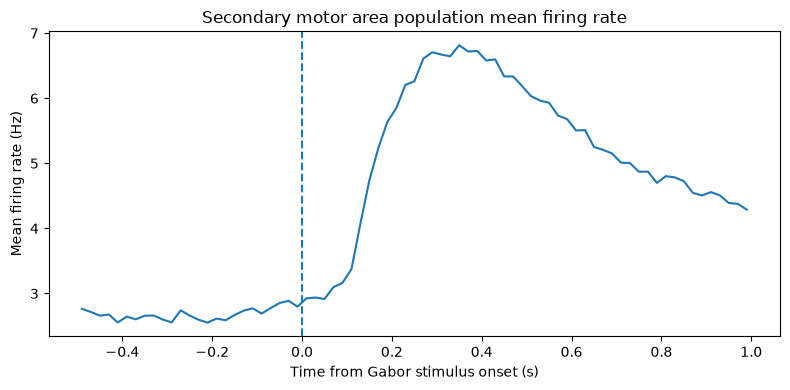

In [48]:
# Plot mean firing rate across all valid trials and units

import matplotlib.pyplot as plt


population_mean_rate_hz = (
    firing_rates_hz.mean(
        axis=(0, 1)
    )
)


plt.figure(
    figsize=(8, 4)
)

plt.plot(
    time_bin_centers_s,
    population_mean_rate_hz,
)

plt.axvline(
    0,
    linestyle="--",
)

plt.xlabel(
    "Time from Gabor stimulus onset (s)"
)

plt.ylabel(
    "Mean firing rate (Hz)"
)

plt.title(
   TARGET_REGION + " population mean firing rate"
)

plt.tight_layout()
plt.show()

In [52]:
# Save stimulus-aligned binned spike data

BINNED_SPIKES_PATH = (
    SESSION_OUTPUT_DIR
    / "stimulus_aligned_spike_counts.npz"
)


np.savez_compressed(
    BINNED_SPIKES_PATH,

    # 主要数据
    spike_counts=spike_counts,

    # 时间信息
    time_bin_edges_s=time_bin_edges_s,
    time_bin_centers_s=time_bin_centers_s,

    # 保证 trial 和 unit 顺序可以还原
    trial_index=(
        analysis_trials_df[
            "trial_index"
        ]
        .astype(int)
        .to_numpy()
    ),
    unit_index=selected_unit_indices,

    # 分箱参数
    alignment_event=np.asarray(
        ALIGN_EVENT_COLUMN
    ),
    time_start_s=np.asarray(
        TIME_START_S
    ),
    time_end_s=np.asarray(
        TIME_END_S
    ),
    bin_size_s=np.asarray(
        BIN_SIZE_S
    ),
)


print(
    "Saved:",
    BINNED_SPIKES_PATH,
)

Saved: D:\Ephys_analysis\ibl-population-dynamics\results\prototype_sessions\4d8c7767-981c-4347-8e5e-5d5fffe38534\stimulus_aligned_spike_counts.npz


In [53]:
# Reload saved binned data and verify

loaded_binned_data = np.load(
    BINNED_SPIKES_PATH,
    allow_pickle=False,
)


loaded_spike_counts = (
    loaded_binned_data[
        "spike_counts"
    ]
)

loaded_time_centers_s = (
    loaded_binned_data[
        "time_bin_centers_s"
    ]
)

loaded_trial_indices = (
    loaded_binned_data[
        "trial_index"
    ]
)

loaded_unit_indices = (
    loaded_binned_data[
        "unit_index"
    ]
)


assert np.array_equal(
    loaded_spike_counts,
    spike_counts,
)

assert np.allclose(
    loaded_time_centers_s,
    time_bin_centers_s,
)

assert np.array_equal(
    loaded_trial_indices,
    analysis_trials_df[
        "trial_index"
    ].astype(int).to_numpy(),
)

assert np.array_equal(
    loaded_unit_indices,
    selected_unit_indices,
)


print(
    "Reload verification passed."
)

print(
    "Loaded shape:",
    loaded_spike_counts.shape,
)

Reload verification passed.
Loaded shape: (545, 135, 75)


In [51]:
# Close remote NWB resources

io.close()
h5py_file.close()
rem_file.close()

print(
    "Remote NWB resources closed."
)

Remote NWB resources closed.
